# 第093讲可执行实验

先阅读lecture.md与lab.md，再重启内核从上到下执行。所有数据本地合成；不调用网络、GPU或付费模型。输出会覆盖本讲可再生的outputs/figures；探索实验请复制目录。

## 1 核对环境与工作目录
Notebook依赖同目录experiment.py。不要只下载.ipynb。

In [1]:
from pathlib import Path
import sys, json
import numpy as np
ROOT = Path.cwd()
assert (ROOT / "experiment.py").exists(), "请切换到本讲目录"
print("Python:", sys.version.split()[0], "NumPy:", np.__version__)

Python: 3.12.14 NumPy: 2.3.5


## 2 阅读实现并形成预测
下面列出核心实验源码。先对照讲义找出数据生成、模型或解析场、积分与评价四个位置。代码内注释解释形状、方向与边界。

In [2]:
import inspect
import experiment
print(inspect.getsource(experiment))

"""DL093: Gaussian denoising score matching, a linear baseline (not a neural net)."""
from pathlib import Path
import os
os.environ.setdefault('MPLCONFIGDIR', '/tmp/dl093-mpl')
import json
import numpy as np
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt

ROOT = Path(__file__).resolve().parent
MU = np.array([0.7, -0.4])
COV = np.array([[1.0, 0.55], [0.55, 1.8]])
SIGMA = 0.6

def score(x, sigma=SIGMA):
    """Row-vector convention: each row is one point; gradient has same shape."""
    return -(np.asarray(x) - MU) @ np.linalg.inv(COV + sigma**2 * np.eye(2))

def sample(rng, n, sigma=SIGMA):
    clean = rng.multivariate_normal(MU, COV, n)
    noise = rng.normal(size=(n, 2))
    noisy = clean + sigma * noise
    # Target is the conditional corruption score, not the marginal score.
    return clean, noisy, -noise / sigma

def fit(noisy, target):
    design = np.column_stack([noisy, np.ones(len(noisy))])
    return np.linalg.lstsq(design, target, rcond=None)[0]

def

## 3 从头重新运行实验
这会真实生成样本、计算指标并重建图形；不是展示缓存结果。

In [3]:
results = experiment.main()

{
  "seed_train": 9301,
  "seed_test": 9302,
  "n_train": 60000,
  "n_test": 30000,
  "sigma": 0.6,
  "model": "affine least-squares DSM; not a deep network",
  "score_mse_per_coordinate": 0.00013951473124586004,
  "test_dsm_mse_per_coordinate": 2.0827888789654865,
  "oracle_test_dsm_mse_per_coordinate": 2.0827534069252116,
  "coefficient_max_absolute_error": 0.004539532658185186,
  "groups": {
    "central_r2_lt_2": {
      "n": 18925,
      "score_mse_per_coordinate": 0.0001145452319895337
    },
    "middle_r2_2_to_6": {
      "n": 9623,
      "score_mse_per_coordinate": 0.0001685190246127374
    },
    "tail_r2_ge_6": {
      "n": 1452,
      "score_mse_per_coordinate": 0.00027273749870902444
    }
  },
  "uniform_grid_score_mse_per_coordinate": 0.0002604545698898832
}


## 4 核对持久化证据
先看每个数组的形状与是否有限，再解释指标。

In [4]:
saved = json.loads((ROOT / "outputs/metrics.json").read_text())
print(json.dumps(saved, ensure_ascii=False, indent=2))
with np.load(ROOT / "outputs/data.npz") as data:
    for key in data.files:
        a = data[key]
        print(key, a.shape, "finite:", bool(np.isfinite(a).all()))

{
  "seed_train": 9301,
  "seed_test": 9302,
  "n_train": 60000,
  "n_test": 30000,
  "sigma": 0.6,
  "model": "affine least-squares DSM; not a deep network",
  "score_mse_per_coordinate": 0.00013951473124586004,
  "test_dsm_mse_per_coordinate": 2.0827888789654865,
  "oracle_test_dsm_mse_per_coordinate": 2.0827534069252116,
  "coefficient_max_absolute_error": 0.004539532658185186,
  "groups": {
    "central_r2_lt_2": {
      "n": 18925,
      "score_mse_per_coordinate": 0.0001145452319895337
    },
    "middle_r2_2_to_6": {
      "n": 9623,
      "score_mse_per_coordinate": 0.0001685190246127374
    },
    "tail_r2_ge_6": {
      "n": 1452,
      "score_mse_per_coordinate": 0.00027273749870902444
    }
  },
  "uniform_grid_score_mse_per_coordinate": 0.0002604545698898832
}
clean_train (60000, 2) finite: True
noisy_train (60000, 2) finite: True
conditional_targets (60000, 2) finite: True
test (30000, 2) finite: True
test_conditional_targets (30000, 2) finite: True
test_score (30000, 2) 

## 5 看完整图，不挑漂亮样本
图与讲义对应。观察不符合直觉的地方，结合指标解释。

01_density_score.png


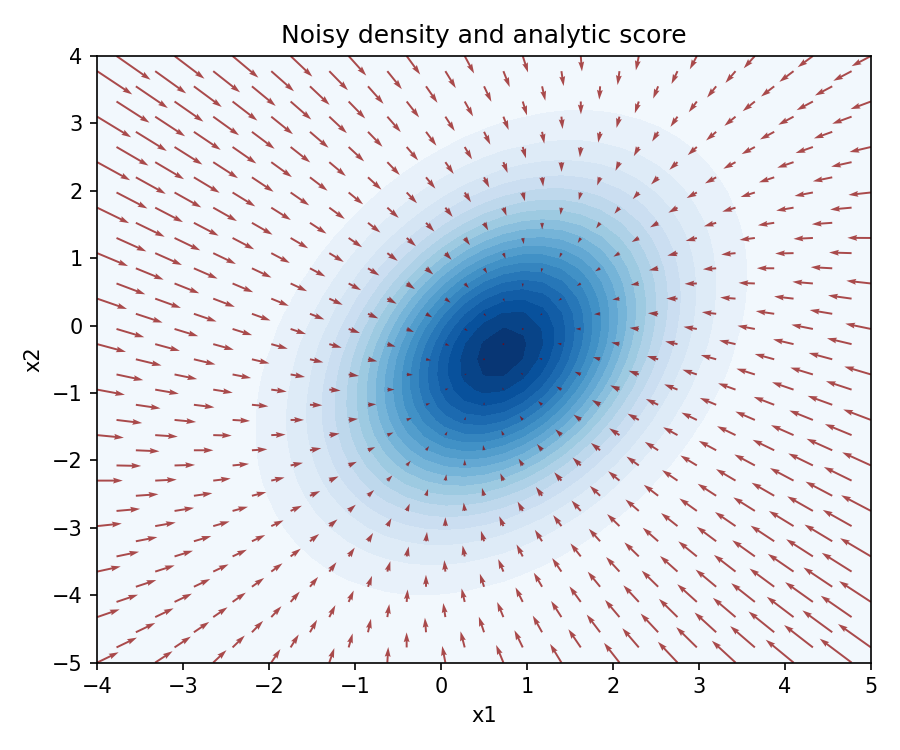

02_error_regions.png


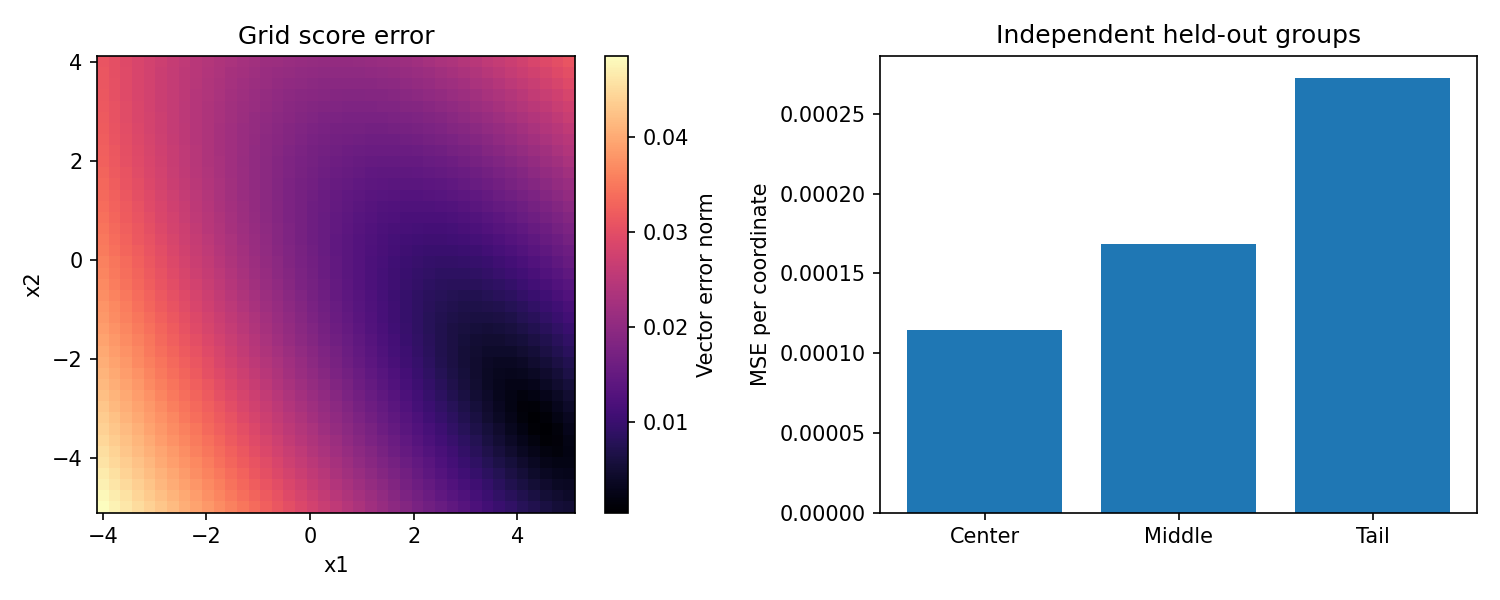

03_noise_scales.png


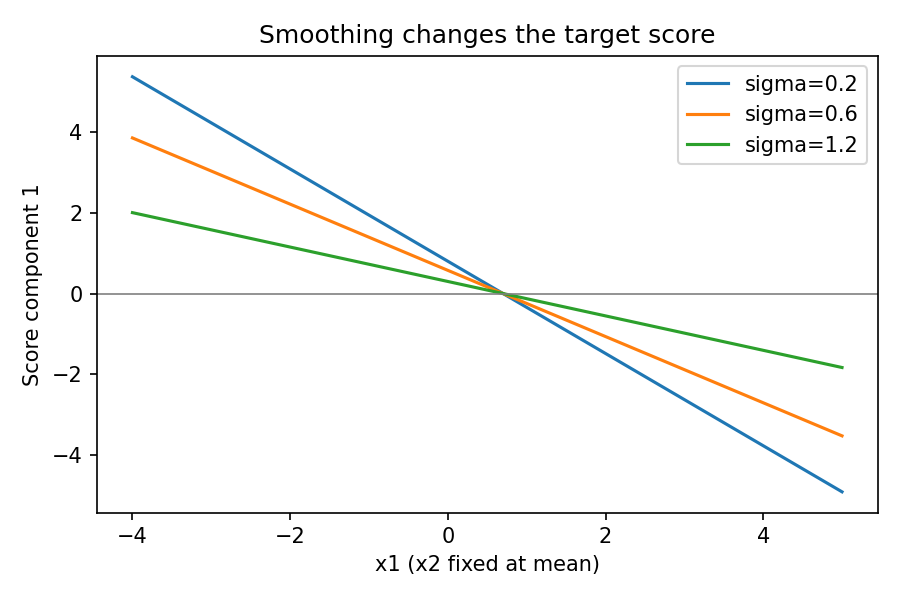

In [5]:
from IPython.display import display, Image
for figure in sorted((ROOT / "figures").glob("*.png")):
    print(figure.name)
    display(Image(filename=str(figure), width=760))

## 6 执行独立断言
测试通过只覆盖这些明确断言，不等于现实部署验证。之后按lab.md做一个受控变化。

In [6]:
import unittest
import tests
suite = unittest.defaultTestLoader.loadTestsFromModule(tests)
result = unittest.TextTestRunner(verbosity=2).run(suite)
assert result.wasSuccessful()

test_exact_affine_recovery (tests.ScoreTests.test_exact_affine_recovery) ... 

ok


test_gradient_finite_difference (tests.ScoreTests.test_gradient_finite_difference) ... 

ok


test_saved_run (tests.ScoreTests.test_saved_run) ... 

ok


test_target_identity (tests.ScoreTests.test_target_identity) ... 

ok


----------------------------------------------------------------------
Ran 4 tests in 0.025s

OK


## 反思与交付
写清本实验是学习模型还是解析score、样本数和种子、主要误差来源、实际结果与未检验范围。练习详解见answers.md。